In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df=pd.read_csv(r"C:\Users\hp\Downloads\archive (1)\Walmart.csv")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [3]:
print("First 5 rows:")
display(df.head())

print("Dataset shape:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data types and missing values:")
df.info()

print("Statistical summary:")
display(df.describe(include="all"))

First 5 rows:


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


Dataset shape:
(6435, 8)
Column names:
['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB
Statistical summary:


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
unique,NaN,143,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,05-02-2010,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,45,NaN,NaN,NaN,NaN,NaN,NaN
mean,23.000000,NaN,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,NaN,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,NaN,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,NaN,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,NaN,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000


In [4]:
# Count missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates()

# Convert column names to lowercase and replace spaces
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Cleaned column names:")
print(df.columns.tolist())

print("Dataset shape after removing duplicates:")
print(df.shape)

Missing values before cleaning:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
Duplicate rows: 0
Cleaned column names:
['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature', 'fuel_price', 'cpi', 'unemployment']
Dataset shape after removing duplicates:
(6435, 8)


In [5]:
# Check missing values again
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

display(missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
))

# Convert suitable date columns if one exists
for col in df.columns:
    if "date" in col:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print(df.dtypes)

,Missing_Count,Missing_Percentage
store,0,0.0
date,0,0.0
weekly_sales,0,0.0
holiday_flag,0,0.0
temperature,0,0.0
fuel_price,0,0.0
cpi,0,0.0
unemployment,0,0.0


store                    int64
date            datetime64[ns]
weekly_sales           float64
holiday_flag             int64
temperature            float64
fuel_price             float64
cpi                    float64
unemployment           float64
dtype: object


In [6]:
numeric_df = df.select_dtypes(include=np.number)

print("Numerical columns:")
print(numeric_df.columns.tolist())

display(numeric_df.describe().T)

print("Mean:")
display(numeric_df.mean())

print("Median:")
display(numeric_df.median())

print("Standard deviation:")
display(numeric_df.std())

print("Correlation matrix:")
display(numeric_df.corr())

Numerical columns:
['store', 'weekly_sales', 'holiday_flag', 'temperature', 'fuel_price', 'cpi', 'unemployment']


,count,mean,std,min,25%,50%,75%,max
store,6435.0,2.300000e+01,12.988182,1.000,12.000,23.000000,3.400000e+01,4.500000e+01
weekly_sales,6435.0,1.046965e+06,564366.622054,209986.250,553350.105,960746.040000,1.420159e+06,3.818686e+06
holiday_flag,6435.0,6.993007e-02,0.255049,0.000,0.000,0.000000,0.000000e+00,1.000000e+00
temperature,6435.0,6.066378e+01,18.444933,-2.060,47.460,62.670000,7.494000e+01,1.001400e+02
fuel_price,6435.0,3.358607e+00,0.459020,2.472,2.933,3.445000,3.735000e+00,4.468000e+00
cpi,6435.0,1.715784e+02,39.356712,126.064,131.735,182.616521,2.127433e+02,2.272328e+02
unemployment,6435.0,7.999151e+00,1.875885,3.879,6.891,7.874000,8.622000e+00,1.431300e+01


Mean:


store           2.300000e+01
weekly_sales    1.046965e+06
holiday_flag    6.993007e-02
temperature     6.066378e+01
fuel_price      3.358607e+00
cpi             1.715784e+02
unemployment    7.999151e+00
dtype: float64

Median:


store               23.000000
weekly_sales    960746.040000
holiday_flag         0.000000
temperature         62.670000
fuel_price           3.445000
cpi                182.616521
unemployment         7.874000
dtype: float64

Standard deviation:


store               12.988182
weekly_sales    564366.622054
holiday_flag         0.255049
temperature         18.444933
fuel_price           0.459020
cpi                 39.356712
unemployment         1.875885
dtype: float64

Correlation matrix:


,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
store,1.000000e+00,-0.335332,-4.386841e-16,-0.022659,0.060023,-0.209492,0.223531
weekly_sales,-3.353320e-01,1.000000,3.689097e-02,-0.063810,0.009464,-0.072634,-0.106176
holiday_flag,-4.386841e-16,0.036891,1.000000e+00,-0.155091,-0.078347,-0.002162,0.010960
temperature,-2.265908e-02,-0.063810,-1.550913e-01,1.000000,0.144982,0.176888,0.101158
fuel_price,6.002295e-02,0.009464,-7.834652e-02,0.144982,1.000000,-0.170642,-0.034684
cpi,-2.094919e-01,-0.072634,-2.162091e-03,0.176888,-0.170642,1.000000,-0.302020
unemployment,2.235313e-01,-0.106176,1.096028e-02,0.101158,-0.034684,-0.302020,1.000000


In [7]:
for col in numeric_df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Outlier count:", len(outliers))


Column: store
Lower bound: -21.0
Upper bound: 67.0
Outlier count: 0

Column: weekly_sales
Lower bound: -746862.7275
Upper bound: 2720371.4924999997
Outlier count: 34

Column: holiday_flag
Lower bound: 0.0
Upper bound: 0.0
Outlier count: 450

Column: temperature
Lower bound: 6.240000000000002
Upper bound: 116.16
Outlier count: 3

Column: fuel_price
Lower bound: 1.7299999999999998
Upper bound: 4.938
Outlier count: 0

Column: cpi
Lower bound: 10.222559825000019
Upper bound: 334.255733625
Outlier count: 0

Column: unemployment
Lower bound: 4.2945
Upper bound: 11.218499999999999
Outlier count: 481


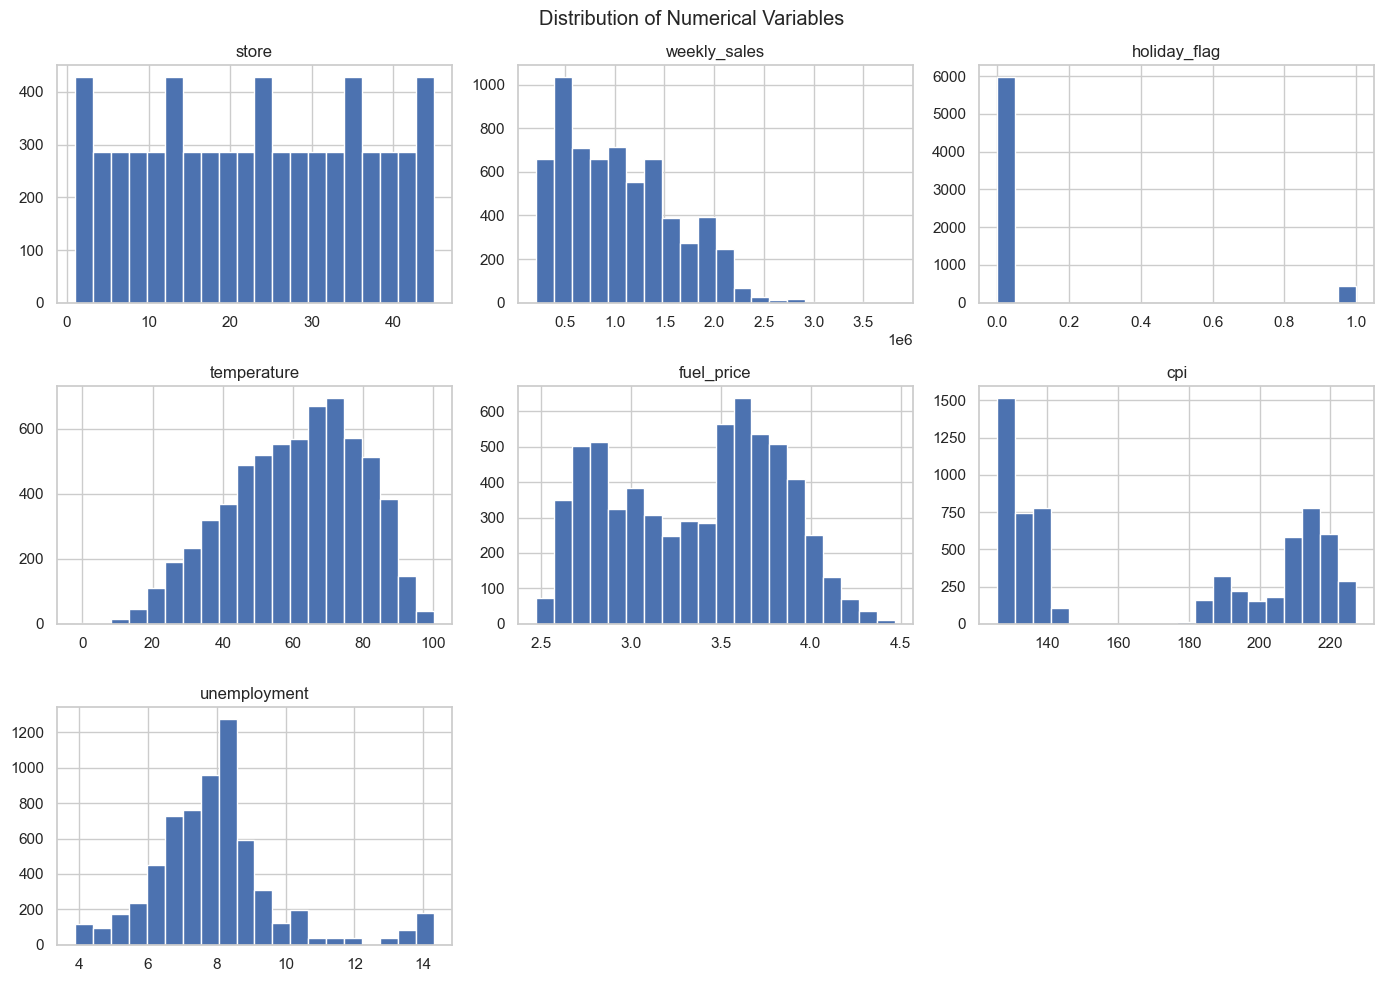

In [8]:
numeric_df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

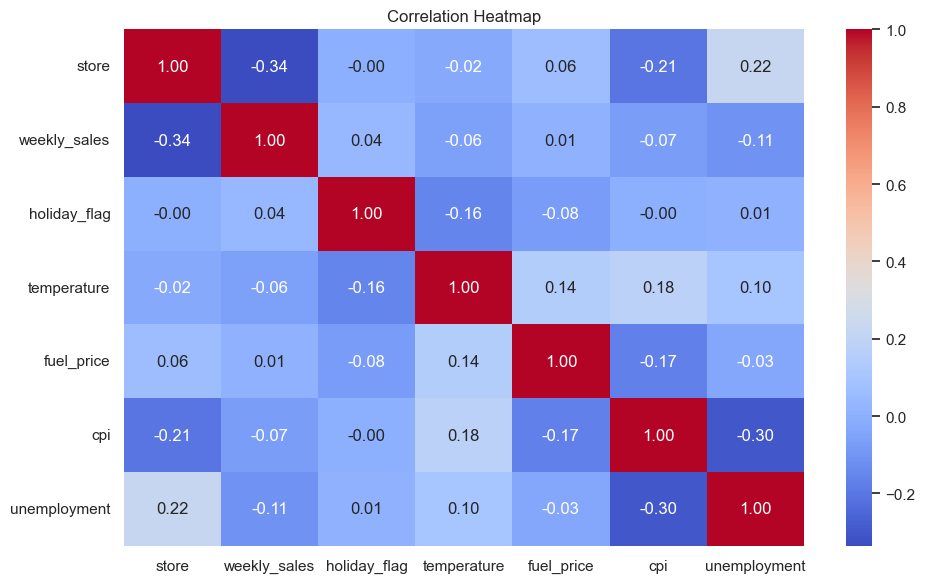

In [9]:
if not numeric_df.empty:
    plt.figure(figsize=(10, 6))

    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

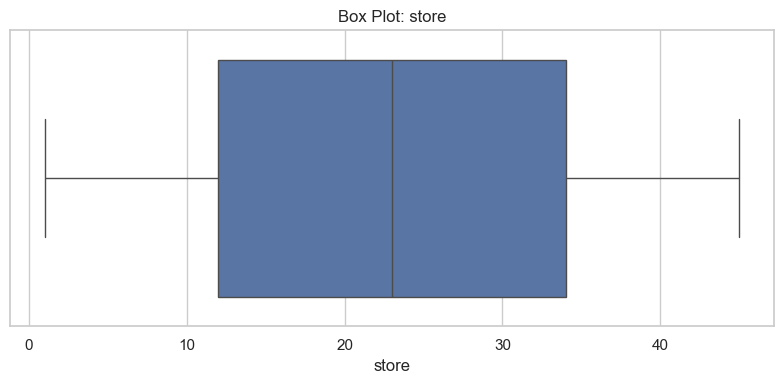

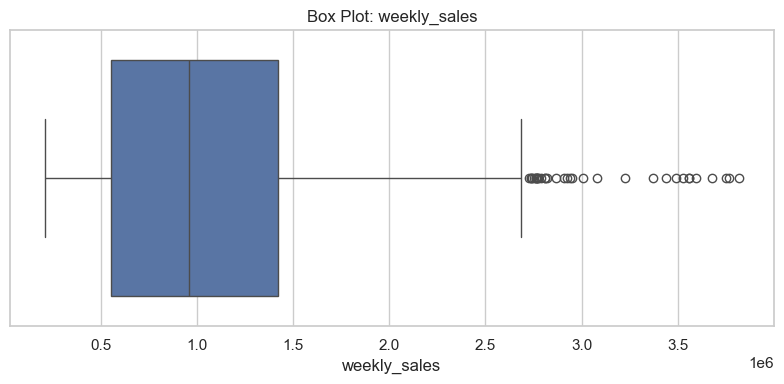

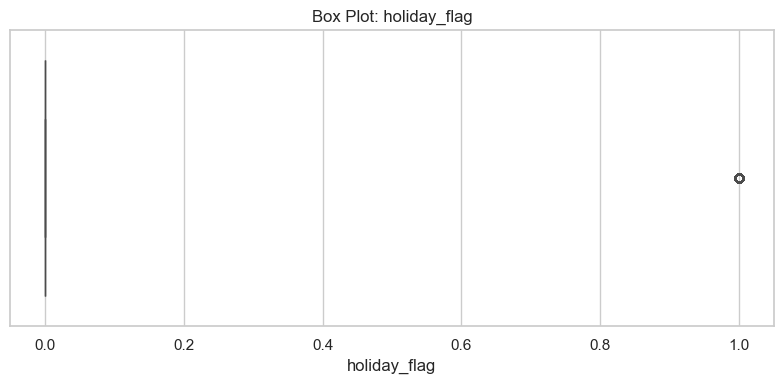

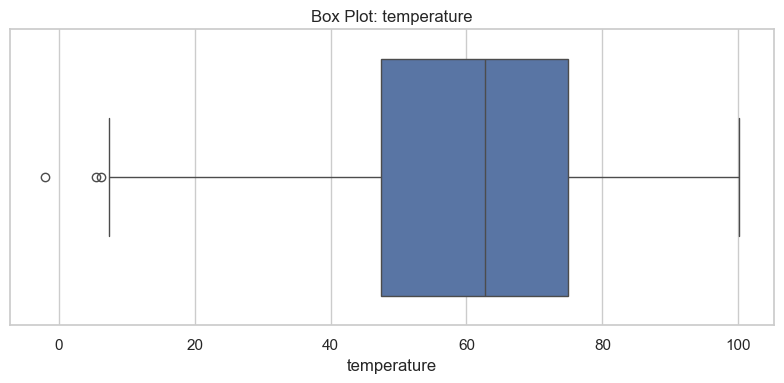

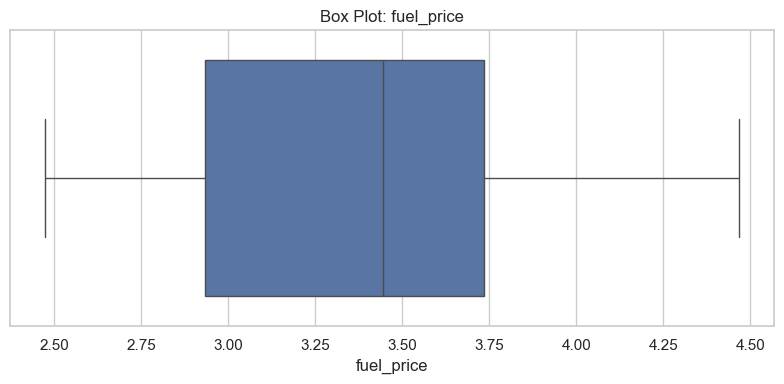

In [10]:
for col in numeric_df.columns[:5]:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Box Plot: {col}")
    plt.tight_layout()
    plt.show()

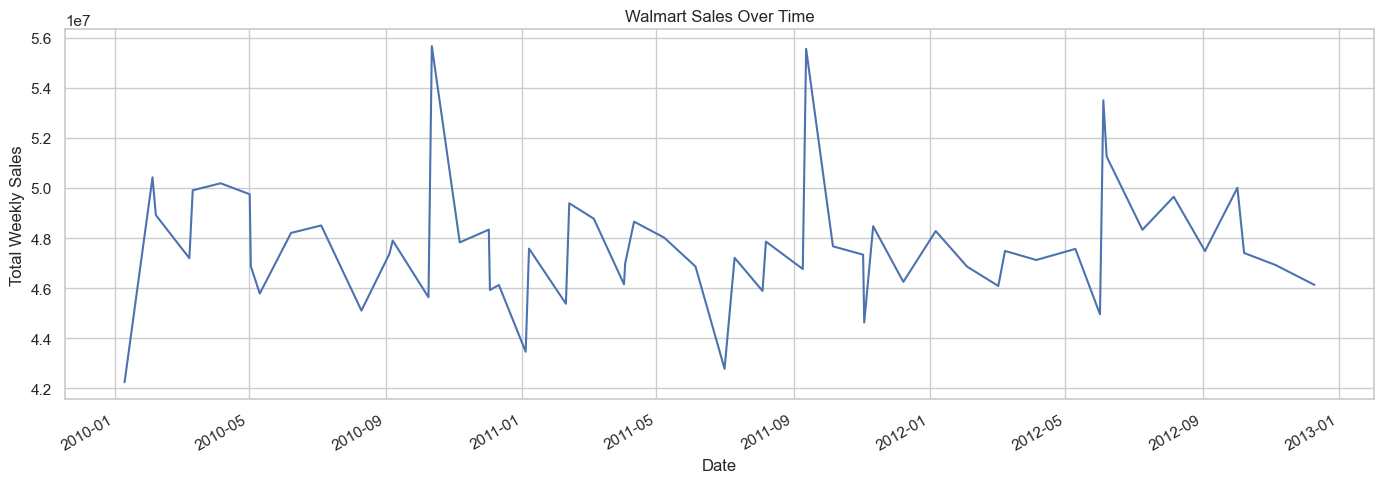

Total sales: 2718571558.01
Average weekly sales: 1059871.952440546
Highest weekly sale: 2752122.08


In [11]:
# Run this cell only if these columns exist
if {"date", "weekly_sales"}.issubset(df.columns):

    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    df = df.dropna(subset=["date"])

    daily_sales = (
        df.groupby("date")["weekly_sales"]
        .sum()
        .sort_index()
    )

    plt.figure(figsize=(14, 5))
    daily_sales.plot()

    plt.title("Walmart Sales Over Time")
    plt.xlabel("Date")
    plt.ylabel("Total Weekly Sales")
    plt.tight_layout()
    plt.show()

    print("Total sales:", df["weekly_sales"].sum())
    print("Average weekly sales:", df["weekly_sales"].mean())
    print("Highest weekly sale:", df["weekly_sales"].max())

Top 10 stores by total recorded weekly sales:


store
20    1.236541e+08
4     1.190478e+08
14    1.182858e+08
13    1.138956e+08
2     1.112614e+08
10    1.085998e+08
27    1.016186e+08
1     9.130517e+07
6     9.056853e+07
19    8.371544e+07
Name: weekly_sales, dtype: float64

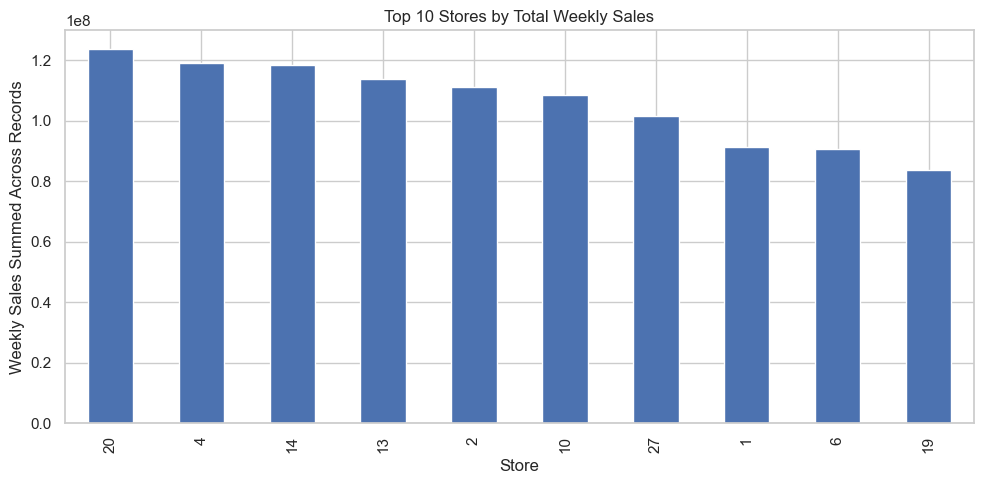

In [12]:
if {"store", "weekly_sales"}.issubset(df.columns):

    store_sales = (
        df.groupby("store")["weekly_sales"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Top 10 stores by total recorded weekly sales:")
    display(store_sales.head(10))

    store_sales.head(10).plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Top 10 Stores by Total Weekly Sales")
    plt.xlabel("Store")
    plt.ylabel("Weekly Sales Summed Across Records")
    plt.tight_layout()
    plt.show()

,mean,median,count
holiday_flag,,,
0,1.059765e+06,977070.62,2295
1,1.060778e+06,1002110.01,270


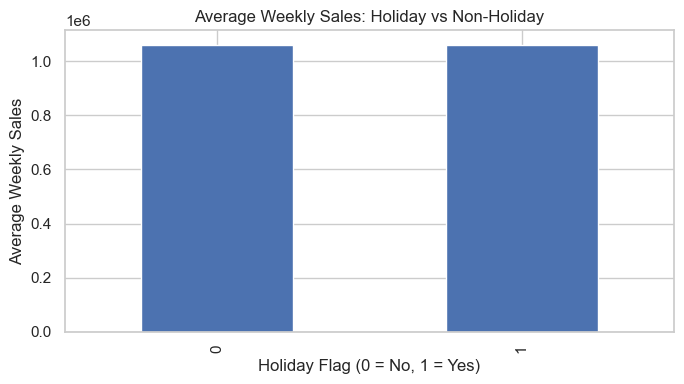

In [13]:
if {"holiday_flag", "weekly_sales"}.issubset(df.columns):

    holiday_analysis = (
        df.groupby("holiday_flag")["weekly_sales"]
        .agg(["mean", "median", "count"])
    )

    display(holiday_analysis)

    holiday_analysis["mean"].plot(
        kind="bar",
        figsize=(7, 4)
    )

    plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
    plt.xlabel("Holiday Flag (0 = No, 1 = Yes)")
    plt.ylabel("Average Weekly Sales")
    plt.tight_layout()
    plt.show()

In [14]:
print("=" * 50)
print("WALMART DATA ANALYSIS REPORT")
print("=" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Duplicate rows remaining:", df.duplicated().sum())

print("\nMissing values by column:")
print(df.isnull().sum())

print("\nNumerical summary:")
display(df.select_dtypes(include=np.number).describe().T)

print("\nAnalysis completed.")

WALMART DATA ANALYSIS REPORT
Number of rows: 2565
Number of columns: 8
Duplicate rows remaining: 0

Missing values by column:
store           0
date            0
weekly_sales    0
holiday_flag    0
temperature     0
fuel_price      0
cpi             0
unemployment    0
dtype: int64

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
store,2565.0,2.300000e+01,12.989706,1.000000,12.000000,23.000000,3.400000e+01,4.500000e+01
weekly_sales,2565.0,1.059872e+06,557383.102302,209986.250000,570069.480000,981345.200000,1.450733e+06,2.752122e+06
holiday_flag,2565.0,1.052632e-01,0.306952,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
temperature,2565.0,5.958586e+01,19.069276,-2.060000,45.260000,61.100000,7.457000e+01,1.000700e+02
fuel_price,2565.0,3.329579e+00,0.461985,2.513000,2.868000,3.417000,3.702000e+00,4.468000e+00
cpi,2565.0,1.713863e+02,39.293112,126.085452,131.586613,182.598306,2.125126e+02,2.271694e+02
unemployment,2565.0,8.022267e+00,1.878158,3.879000,6.908000,7.907000,8.622000e+00,1.431300e+01



Analysis completed.
